In [4]:
# 출력 구조화 Pydantic 스키마 + with_structured_output()

from pydantic import BaseModel, Field
from langchain.chat_models import init_chat_model

from dotenv import load_dotenv

load_dotenv()

# 1) 스키마 정의
class SearchQuery(BaseModel):
    search_query: str = Field(..., description="웹 검색에 최적화된 질의문")
    justification: str = Field(..., description="해당 질의가 왜 적절한지의 근거")

# 2) 구조화된 출력으로 LLM 래핑
llm = init_chat_model("openai:gpt-4.1")
structured_llm = llm.with_structured_output(SearchQuery)

# 3) 프롬프트 실행
prompt = "랭그래프가 왜 필요한가?"
result = structured_llm.invoke(prompt)

# 4) 사용
print("검색어:", result.search_query)
print("근거:", result.justification)

검색어: 랭그래프의 필요성
근거: 이 질문은 랭그래프라는 기술(아마도 LLM 등에서 사용하는 의미 있어 보이는 그래프 구조나 새로운 데이터 표현 기법)에 대해 그것이 왜 도입되고 필요한지, 기존 방식 대비 어떤 장점이 있는지 궁금해하는 질문이다. '랭그래프'의 정의와 함께 그 필요성을 최신 정보로 찾아 설명할 필요가 있다.


In [9]:
# bind_tools() : LLM은 호출을 결정, 실행은 코드가

# 1) 도구 정의
def multiply(a:int, b:int) -> int:
    """두 수의 곱을 반환"""
    return a * b

# 2) LLM에 도구 바인딩
llm_with_tools = llm.bind_tools([multiply])

# 3) 사용자 질문
user_msg = "21,234,412 곱하기 321,423은?"

# 4) 1차 LLM 호출 -> 도구 호출 의도 파악
msg = llm_with_tools.invoke(user_msg)

# 5) tool_calls 확인 및 실행
results = {}
print(msg.tool_calls)

for call in getattr(msg, "tool_calls", []):
    name = call["name"]
    args = call["args"]
    if name =="multiply":
        results[name] = multiply(**args)
print(results)

[{'name': 'multiply', 'args': {'a': 21234412, 'b': 321423}, 'id': 'call_nEIyez7N60cj6d5NZCHQHYPq', 'type': 'tool_call'}]
{'multiply': 6825228408276}


# 프롬프트 체이닝
topic -> joke -> improved_joke -> final_joke

In [10]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    final_joke: str

In [11]:
# 1 농담 생성 : topic으로 짧은 농담 생성 (노드)
def generate_joke(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 짧은 농담을 작성해 주세요.")
    return {"joke":msg.content}

# 2 품질 검사 (펀치라인 확인) : Pass/Fail 라벨 반환 (라우팅 함수)
def check_punchline(state: State):
    if "?" in state["joke"] or "!" in state["joke"]:
        return "Pass"
    return "Fail"

# 3 농담 개선 : 말장난 추가
def improve_joke(state: State):
    msg = llm.invoke(f"다음 농담에 말장난을 넣어 더 재미있게 만들어 주세요: {state['joke']}")
    return {"improved_joke":msg.content}

# 4 농담 다듬기 : 예상치 못한 반전 추가
def polish_joke(state: State):
    msg = llm.invoke(f"다음 농담에 예상치 못한 반전을 추가해 주세요: {state['improved_joke']}")
    return {"final_joke": msg.content}


In [12]:
# 워크플로우 구성 : 조건부 분기

workflow = StateGraph(State)

# 노드 등록
workflow.add_node("generate_joke", generate_joke)
workflow.add_node("improve_joke", improve_joke)
workflow.add_node("polish_joke", polish_joke)

# 순서 연결
workflow.add_edge(START, "generate_joke")
workflow.add_conditional_edges(
    "generate_joke", check_punchline,
    {"Fail":"improve_joke", "Pass":END}
)
workflow.add_edge("improve_joke", "polish_joke")
workflow.add_edge("polish_joke", END)

chain = workflow.compile() # 워크플로우 컴파일

In [24]:
state = chain.invoke({"topic":"한국"})
print("Initial joke:"); print(state["joke"])

if "improved_joke" in state:
    print("Improved joke:"); print(state["improved_joke"])
    print("Final joke:"); print(state["final_joke"])
else:
    print("농담이 품질 검사를 통과하여 개선이 필요하지 않습니다!")

Initial joke:
한국에 대한 짧은 농담을 드릴게요!

"한국에서 제일 빠른 동물은?  
바로 '빨리빨리'!"
농담이 품질 검사를 통과하여 개선이 필요하지 않습니다!


# 병렬 처리
topic -> joke / story / poem 저장 -> combined_output 로 합침

In [25]:
class State(TypedDict):
    topic: str
    joke: str
    story: str
    poem: str
    combined_output: str

# 1) 농담생성
def call_llm_1(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 농담을 작성해 주세요.")
    return {"joke":msg.content}

# 2) 이야기 생성
def call_llm_2(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 이야기를 작성해 주세요.")
    return {"story":msg.content}

# 3) 시 생성
def call_llm_3(state: State):
    msg = llm.invoke(f"{state['topic']}에 대한 시를 작성해 주세요.")
    return {"poem":msg.content}

In [26]:
def aggregator(state: State):
    combined = f"{state['topic']}에 관한 이야기, 농담, 시 입니다 !\n\n"
    combined += f"이야기:\n{state['story']}\n\n"
    combined += f"농담:\n{state['joke']}\n\n"
    combined += f"시:\n{state['poem']}"
    return {"combined_output":combined}

In [28]:
# 워크플로우 구성

parallel_builder = StateGraph(State)

# 노드 등록
parallel_builder.add_node("call_llm_1", call_llm_1)
parallel_builder.add_node("call_llm_2", call_llm_2)
parallel_builder.add_node("call_llm_3", call_llm_3)
parallel_builder.add_node("aggregator", aggregator)

# 병렬 연결
parallel_builder.add_edge(START, "call_llm_1")
parallel_builder.add_edge(START, "call_llm_2")
parallel_builder.add_edge(START, "call_llm_3")

# 결과 합치기
parallel_builder.add_edge("call_llm_1", "aggregator")
parallel_builder.add_edge("call_llm_2", "aggregator")
parallel_builder.add_edge("call_llm_3", "aggregator")
parallel_builder.add_edge("aggregator", END)

# 컴파일
parallel_workflow = parallel_builder.compile()


In [ ]:
# 실행

state = parallel_workflow.invoke({"topic":"한국"})
print(state["combined_output"])

한국에 관한 이야기, 농담, 시 입니다 !

이야기:
한국은 동아시아에 위치한 한반도에 자리 잡은 나라입니다. 공식적으로는 대한민국(大韓民國, Republic of Korea)라고 부르며, 수도는 서울입니다. 한국은 북쪽으로 북한(조선민주주의인민공화국)과 접경하고 있고, 동쪽으로는 동해(일본해), 서쪽으로는 황해, 남쪽으로는 대한해협을 사이에 두고 일본과 이웃하고 있습니다.

**역사적으로** 한국은 약 오천 년에 걸친 유구한 역사를 가지고 있습니다. 고조선에서 시작하여 삼국시대(고구려·백제·신라), 통일신라, 고려, 조선 등 다양한 왕조가 번성하였고, 20세기 초 일본의 식민통치를 받기도 했습니다. 1945년 광복 이후 남북으로 분단되어 현재에 이르고 있습니다.

**경제**적으로 한국은 전쟁의 폐허를 딛고 눈부신 성장을 이루어낸 나라로 평가받습니다. 1960년대 이후 '한강의 기적'이라 불리는 빠른 경제 성장을 경험하였으며, 세계에서 손꼽히는 IT 강국이자 선진국이며, 현대자동차, 삼성, LG 등 글로벌 기업들이 활약하고 있습니다.

**문화**적으로도 K-팝, K-드라마, 한류 등으로 전 세계적인 영향력을 보여주고 있습니다. 특히 BTS, 블랙핑크와 같은 음악 그룹, 영화 <기생충>은 국제적으로 큰 인기를 누리고 있습니다. 전통 한복, 한식(김치, 비빔밥, 불고기 등), 한글 등 고유의 독특한 문화유산도 자랑거리입니다.

**사회**적으로 한국은 빠른 기술 발전, 교육 열기, 배달 문화, 다양한 카페와 식당 문화 등, 역동적이며 변화하는 생활상을 보여줍니다. 5천 만 명이 넘는 인구가 좁은 국토에 밀집해서 살아가며, 사계절이 뚜렷한 기후와 산, 바다, 강 등 아름다운 자연환경도 많습니다.

이처럼 한국은 역사와 전통, 현대와 미래가 조화를 이루는 매력적인 나라입니다.

농담:
물론이죠! 한국에 대한 재미있는 농담 하나 드릴게요:

왜 한국 사람들은 시간을 잘 지킬까요?

왜냐하면 “김치” 시간에 맞춰서 항상 “찍”고 오거든요! 😄

(“김치~!” 하고 사

NameError: name 'Image' is not defined

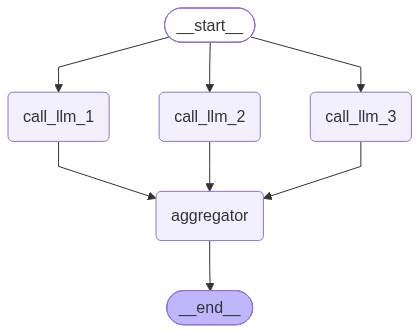

In [30]:
from IPython.display import Image, display

# 다이어그램 출력
display(Image(parallel_workflow.get_graph().draw_mermaid_png()))

# 라우팅


In [37]:
from typing_extensions import Literal
from langchain_core.messages import HumanMessage, SystemMessage

# 1) 라우팅 결정을 위한 구조화 출력 스키마
class Route(BaseModel):
    step: Literal["poem", "story", "joke"] = Field(None, description="라우팅의 다음 단계")

router = llm.with_structured_output(Route) # 2) 라우터 LLM

class State(TypedDict): # 3) 상태 정의
    input: str
    decision: str
    output: str

def llm_call_1(state: State): # 이야기 작성
    result = llm.invoke(f"다음 주제로 짧은 이야기를 작성해 주세요: {state['input']}")
    return {"output":result.content}

def llm_call_2(state: State): # 농담 작성
    result = llm.invoke(f"다음 주제로 짧은 농담을 작성해 주세요: {state['input']}")
    return {"output":result.content}

def llm_call_3(state: State): # 시 작성
    result = llm.invoke(f"다음 주제로 짧은 시를 작성해 주세요: {state['input']}")
    return {"output":result.content}

def llm_call_router(state: State): # 입력을 적절한 노드로 라우팅
    decision = router.invoke([
        SystemMessage(content="사용자 요청을 이야기(story), 농담(joke), 시(poem) 중 하나로 분류하고 가장 알맞은 항목을 step에 지정하세요."),
        HumanMessage(content=state["input"]),
    ])
    return {"decision":decision.step}

def route_decision(state: State): # 5) 조건부 엣지 분기 로직
    if state["decision"] == "story": return "llm_call_1"
    elif state["decision"] == "joke": return "llm_call_2"
    elif state["decision"] == "poem": return "llm_call_3"

# 6) 워크플로우 구성
router_builder = StateGraph(State)
router_builder.add_node("llm_call_1", llm_call_1)
router_builder.add_node("llm_call_2", llm_call_2)
router_builder.add_node("llm_call_3", llm_call_3)
router_builder.add_node("llm_call_router", llm_call_router)

router_builder.add_edge(START, "llm_call_router")
router_builder.add_conditional_edges(
    "llm_call_router",
    route_decision,
    {
        "llm_call_1":"llm_call_1",
        "llm_call_2":"llm_call_2",
        "llm_call_3":"llm_call_3"
    },
)

router_builder.add_edge("llm_call_1", END)
router_builder.add_edge("llm_call_2", END)
router_builder.add_edge("llm_call_3", END)

router_workflow = router_builder.compile()

state = router_workflow.invoke({"input":"한국에 대한 농담을 써 주세요"})
print(state["output"])

한국에 대한 짧은 농담 하나 드릴게요!

"한국에서 제일 인기 많은 게임은 뭔지 아세요?  
바로… ‘치킨’ 배달 게임이에요.  
늦게 올수록 스릴 있고, 빨리 오면 치킨이 식기 전에 엔딩!"


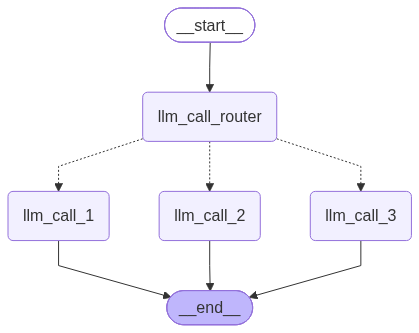

In [50]:
display(Image(router_workflow.get_graph().draw_mermaid_png()))

# 오케스트레이터 - 워커
기본 개념은 병렬 처리와 비슷하지만 오케스트레이터가 입력에 맞춰 하위 작업을
# 동적으로 
생성한다는 점이 핵심 차이임

In [43]:
from typing import Annotated, List
import operator
from langgraph.types import Send
from pydantic import BaseModel, Field

class Section(BaseModel):
    name: str = Field(description="이 보고서 섹션의 제목")
    description: str = Field(description = "이 섹션에서 다룰 주요 주제와 개념 설명")

class Section(BaseModel):
    sections:List[Section] = Field(description="보고서의 각 섹션 목록")

# LLM 구조화 출력 스키마 적용
planner = llm.with_structured_output(Section)

In [44]:
# 전체 워크플로 상태

class State(TypedDict):
    topic: str
    sections: list[Section]
    completed_sections: Annotated[list, operator.add]
    final_report: str

# 워커 상태
class WorkerState(TypedDict):
    section: Section
    completed_Sctions:Annotated[list, operator.add]

In [45]:
# 오케스트레이터 : 주제로 섹션 계획(목차) 생성

def orchestrator(state: State):
    """보고서 목차를 생성하는 오케스트레이터"""
    report_sections = planner.invoke([
        SystemMessage(content="보고서 목차를 생성해 주세요."),
        HumanMessage(content=f"보고서 주제: {state['topic']}"),
    ])
    return {"sections":report_sections.sections}

In [47]:
# 워커 : 할당된 섹션 하나의 본문 작성 (머리말 없이, 마크다운 형식)

def llm_call(state: WorkerState):
    """각 보고서 섹션을 작성하는 워커"""
    section = llm.invoke([
        SystemMessage(content="제공된 제목과 설명에 따라 섹션을 작성하세요. 머리말은 포함하지 말고, 마크다운 형식을 사용하세요."),
        HumanMessage(content=f"섹션 제목: {state['section'].name}\n" f"설명:{state['section'].description}"),
    ])
    return {"completed_sections":[section.content]}

In [48]:
# 종합기 : 작성된 섹션들을 마크다운 구분선 (---)으로 결합

def synthesizer(state: State):
    """작성된 섹션들을 종합하여 최종 보고서 생성"""
    completed_sections = state["completed_sections"]
    combined_report = "\n\n---\n\n".join(completed_sections)
    return {"final_report":combined_report}

In [49]:
# assign_workers : 섹션 수만큼 Send로 워커 실행 지시 생성

def assign_workers(state: State):
    """각 섹션에 워커 할당"""
    return [Send("llm_call", {"section":s}) for s in state["sections"]]

In [51]:
# 워크플로우 구성 / 실행

builder = StateGraph(State)
builder.add_node("orchestrator", orchestrator)
builder.add_node("llm_call", llm_call)
builder.add_node("synthesizer", synthesizer)

builder.add_edge(START, "orchestrator")
builder.add_conditional_edges(
    "orchestrator", assign_workers, ["llm_call"])
builder.add_edge("llm_call", "synthesizer")
builder.add_edge("synthesizer", END)
orchestrator_worker = builder.compile()

state = orchestrator_worker.invoke(
    {"topic":"랭그래프 오케스트레이션-워커 법칙에 관한 보고서"})
print(state["final_report"])

# 1. 서론

본 보고서의 목적은 랭그래프 오케스트레이션-워커 법칙(Orchestration-Worker Law, OWL)의 개념을 체계적으로 분석하고, 이를 바탕으로 인공지능 워크플로우 설계 및 최적화에 미치는 시사점을 제시하는 데 있다. 최근 인공지능 기술의 발전과 함께 대규모 작업의 자동화와 복잡한 프로세스의 효율적 분배에 대한 필요성이 높아지고 있다. 이에 따라 다양한 에이전트가 협력하거나 분업하는 복합적 시스템이 등장하고 있으며, 이러한 시스템의 성능을 극대화하는 원리 탐구가 요구된다.

랭그래프 오케스트레이션-워커 법칙은 오케스트레이션(Orchestration) 시스템과 워커(Worker) 에이전트 간 상호 작용의 구조적 원칙을 이론적으로 정립한 개념적 모델이다. 오케스트레이터는 전체 작업 흐름을 기획하고 부하를 조정하며, 워커들은 세부 작업을 수행하는 역할을 맡는다. 이 법칙은 각 컴포넌트가 맡는 역할과 책임, 그리고 이들이 협업하는 방식이 결과물의 품질과 시스템 효율성에 어떤 영향을 미치는지 설명하며, 복수의 에이전트가 협력하는 분산형 AI 워크플로우 환경에서 최적의 성능 조건에 대한 통찰을 제공한다.

이와 같은 배경 하에 본 보고서는 OWL의 개념과 이론적 근거를 살펴보고, 실제 인공지능 시스템 설계 시 적용 가능성과 한계점을 폭넓게 논의하고자 한다.

---

## 2. 랭그래프 오케스트레이션-워커 법칙의 정의

### 오케스트레이션-워커 법칙이란?

오케스트레이션-워커(Orchestration-Worker) 법칙은 분산 시스템, 특히 랭그래프(LangGraph) 구조에서 중앙 오케스트레이터(Orchestrator)와 개별 워커(Worker)들의 관계 및 역할 분담을 체계적으로 정의한 규칙입니다. 이 법칙은 각 노드가 맡은 역할, 통신 방식, 작업 분배 및 수집 과정을 중심으로 랭그래프 네트워크의 안정적 운영과 확장성을 보장하기 위해 고안되었습니다.

### 기본 원리

- **역할 분리(Segregation of Roles):** 오케스

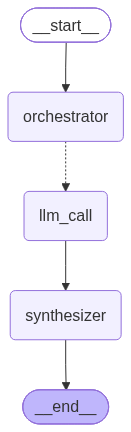

In [52]:
display(Image(orchestrator_worker.get_graph().draw_mermaid_png()))

In [ ]:
# 평가자 - 개선자

In [53]:
# 그래프 상태 + 평가용 구조화 출력 스키마 Feedback + evaluator

class State(TypedDict):
    joke: str # 현재 농담
    topic: str # 주제
    feedback: str # 평가자 피드백(개선 시 참고)
    funny_or_not: str # 평가 등급 ("funny"/ "not funny")

# 평가에 사용할 구조화 출력 스키마
class Feedback(BaseModel):
    grade:Literal["funny", "not funny"] = Field(description="농담이 재미있는지(funny) 아닌지(not funny) 판단하세요.")
    feedback: str = Field(description="재미없다면 어떻게 개선할지 구체적인 피드백을 작성하세요.")

# 평가자 LLM: 구조화 출력으로 등급과 피드백 반환
evaluator = llm.with_structured_output(Feedback)

In [55]:
# 노드 : 생성자(피드백 반영) 평가자
# 생성자 : 피드백이 있으면 반영해 개선, 없으면 새로 생성

def llm_call_generator(state: State):
    if state.get("feedback"):
        msg = llm.invoke(
            f"주제: {state['topic']}\n아래 피드백을 반영하여 더 재밌는"
            f"농담을 작성해 주세요.\n[피드백]: {state['feedback']}")
    else:
        msg = llm.invoke(f"주제: {state['topic']}\n짧고 재치 있는 농담을 작성해 주세요.")
        
    return {"joke":msg.content}

def llm_call_evaluator(state: State):
    grade = evaluator.invoke(
        f"다음 농담이 재미있는지 평가하고, 필요하면 개선 피드백을 주세요. \n"
        f"[농담]: {state['joke']}")
    
    return {"funny_or_not":grade.grade, "feedback":grade.feedback}

In [58]:
# 분기 : 재미있으면 종료 (Accepted), 아니면 생성자로 복귀 (Rejected)

def route_joke(state: State):
    if state["funny_or_not"] == "funny":    return "Accepted"
    elif state["funny_or_not"] == "not funny":return "Rejected + Feedback"

In [59]:
# 생성자 -> 평가자 -> 조건부 엣지로 종료/재생성 -> 컴파일 -> 실행

optimizer_builder = StateGraph(State)
optimizer_builder.add_node("llm_call_generator", llm_call_generator)
optimizer_builder.add_node("llm_call_evaluator", llm_call_evaluator)
optimizer_builder.add_edge(START, "llm_call_generator")
optimizer_builder.add_edge("llm_call_generator", "llm_call_evaluator")
optimizer_builder.add_conditional_edges(
    "llm_call_evaluator", route_joke,
    {"Accepted":END, "Rejected + Feedback": "llm_call_generator"})
optimizer_workflow = optimizer_builder.compile()

state = optimizer_workflow.invoke({"topic":"한국"})
print(state["joke"])

네, 피드백을 반영해 더 자연스럽고 재밌는 농담을 만들어봤어요!

Q: 바다에서 길을 잃은 고래가 한강에 나타난 이유가 뭘까요?  
A: '한류'를 따라 팬미팅하러 온 거예요. 그런데 알고 보니 K-POP 팬미팅이 아니라, 진짜 차가운 물길이었대요!

또는 상황 설정을 바꿔서,

Q: 고래가 요즘 SNS에 자주 등장하는 이유는?  
A: 요즘 한류(韓流) 따라다니느라 바빠서요. 원래는 차가운 바닷물을 따라가다가, 이제는 K-드라마랑 K-POP 팬이라 연예인 따라다닌대요!  

이렇게 자연스러운 설명이나 상황을 추가하니 두 '한류'의 의미가 더 재밌게 연결되는 것 같아요!


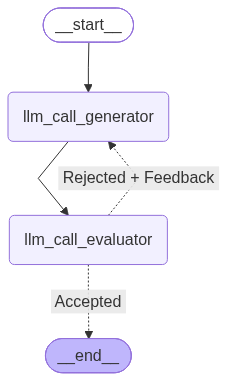

In [60]:
display(Image(optimizer_workflow.get_graph().draw_mermaid_png()))

In [ ]:
# 에이전트
# 미리 단계 수를 정할 수 없는 개방형 문제

In [72]:
from langchain_core.tools import tool

@tool
def multiply(a:int, b:int) -> int:
    """두 수를 곱합니다."""
    return a * b

@tool
def add(a: int, b:int) -> int:
    """두 수를 더합니다."""
    return a + b

@tool
def divide(a: int, b: int) -> float:
    """두 수를 나눕니다."""
    return a / b

tools = [add, multiply, divide]
tools_by_name = {tool.name: tool for tool in tools}
llm_with_tools = llm.bind_tools(tools)

In [73]:
from langgraph.graph import MessagesState
from langchain_core.messages import (SystemMessage, HumanMessage, ToolMessage)

# LLM 호출 노드
def llm_call(state: MessagesState):
    """LLM이 도구 호출 여부를 결정"""
    return {
        "messages":[
            llm_with_tools.invoke(
                [SystemMessage(content="당신은 주어진 입력값으로 산술 연산을 수행하는 유용한 어시스턴트 입니다.")]
                + state["messages"]
            )
        ]
    }

In [74]:
# 도구 실행 노드 : tool_node()
def tool_node(state: dict):
    """LLM이 요청한 도구를 실행"""
    result = []
    for tool_call in state["messages"][-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))

    return {"messages": result}

In [75]:
# 반복 여부 판단 : should_continue()
def should_continue(state: MessagesState):
    """도구 호출이 있으면 계속, 없으면 종료"""
    if state["messages"][-1].tool_calls:
        return "Action"
    return END

In [77]:
# 에이전트 워크플로 구성
agent_builder = StateGraph(MessagesState)
agent_builder.add_node("llm_call", llm_call)
agent_builder.add_node("environment", tool_node)

agent_builder.add_edge(START, "llm_call")
agent_builder.add_conditional_edges(
    "llm_call",
    should_continue,
    {"Action":"environment", END: END},
)
agent_builder.add_edge("environment", "llm_call")

agent = agent_builder.compile()

# 실행
messages = [HumanMessage(content="3과 4를 더하세요.")]
messages = agent.invoke({"messages": messages})
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

3과 4를 더하세요.
================================== Ai Message ==================================
Tool Calls:
  add (call_zwaE3A5XbdJgq6IatJzkTjo7)
 Call ID: call_zwaE3A5XbdJgq6IatJzkTjo7
  Args:
    a: 3
    b: 4
================================= Tool Message =================================

7
================================== Ai Message ==================================

3과 4를 더하면 7입니다.
